## Импорт библиотек

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score


## Загрузка и подготовка данных

Загружен датасет Life Expectancy Data с продолжительностью жизни. .

Поскольку в данных есть пропуски, их необходимо заполнить. Для числовых признаков используем медиану. Категориальный признак `Status` (Developing/Developed) кодируем через `get_dummies`.

Данные разделены на обучающую и тестовую выборки (80/20). Признаки стандартизированы через `StandardScaler`.

In [5]:
# Загружаем датасет
df = pd.read_csv("Life Expectancy Data.csv")

# Убираем пробелы в названиях колонок
df.columns = df.columns.str.strip()

# Удаляем столбец Country — он не нужен для модели
df = df.drop("Country", axis=1)

# Заполняем пропуски медианой
df = df.fillna(df.median(numeric_only=True))

# Кодируем категориальный признак Status
df = pd.get_dummies(df, columns=['Status'], drop_first=True)

# Отделяем целевую переменную
X = df.drop("Life expectancy", axis=1)
y = df["Life expectancy"]

# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Масштабирование
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train) 
X_test = scaler.transform(X_test)

print(X_train.shape)

(2350, 20)


Вывод: Данные очищены от пропусков и закодированы. Признаки масштабированы и готовы к подаче в модели.

## Бинарная классификация

Сведем задачу к классификации. Рассчитаем медиану продолжительности жизни по тренировочной выборке. Страны с показателем выше медианы получили метку 1 (высокая продолжительность жизни), а ниже получили 0.

Обучим логистическую регрессию и посмотрим на вероятности для первых пяти объектов.

In [6]:
# Определяем медиану
median_life = y_train.median()

# Создаем бинарные метки
y_train_class = (y_train > median_life).astype(int)
y_test_class = (y_test > median_life).astype(int)

# Обучаем логистическую регрессию
clf = LogisticRegression(max_iter=2000, random_state=42)
clf.fit(X_train, y_train_class)

# Предсказания
sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])

display(
    pd.DataFrame(
        {
            "Вероятность": sample_probs,
            "Класс": sample_preds,
            "Факт": y_test_class.iloc[:5].values
        }
    ).round(3)
)

print(f"Точность классификации: {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность,Класс,Факт
0,0.298,0,1
1,0.976,1,1
2,0.878,1,1
3,0.985,1,1
4,0.000,0,0


Точность классификации: 0.8861


Вывод: Логистическая регрессия показала высокую точность. Это значит, что социально-экономические и медицинские факторы хорошо разделяют страны на группы с высокой и низкой продолжительностью жизни.

## Регрессия МНК и SGD

Теперь предскажем точное значение продолжительности жизни. Сравним аналитический МНК и итеративный SGD.

Замеряем время обучения. Считаем RMSE (средняя ошибка в годах) и R2 (долю объясненной дисперсии).

In [7]:
# 1. МНК
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time() - start_ols
pred_ols = ols.predict(X_test)

# 2. SGD
start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=2000, tol=1e-3, eta0=0.01, learning_rate="adaptive", random_state=42
)
sgd.fit(X_train, y_train)
time_sgd = time.time() - start_sgd
pred_sgd = sgd.predict(X_test)

# Метрики
rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_sgd)

print(f"МНК: RMSE = {rmse_ols:.2f} лет | R2 = {r2_ols:.2f} | Время = {time_ols:.4f} сек")
print(f"SGD: RMSE = {rmse_sgd:.2f} лет | R2 = {r2_sgd:.2f} | Время = {time_sgd:.4f} сек")

МНК: RMSE = 3.91 лет | R2 = 0.82 | Время = 0.0054 сек
SGD: RMSE = 13.96 лет | R2 = -1.25 | Время = 0.0168 сек


Вывод: МНК показал отличный результат (R2 = 0.82, RMSE = 3.91) и обучился за доли секунды (0.0054). SGD в текущей конфигурации не сошелся: R2 ушел в минус (-1.25), а RMSE до 13.96 лет. Это классическая проблема итеративных методов при неудачно подобранных параметрах (learning rate или количество итераций), тогда как аналитическое решение всегда дает точный ответ.

## Визуализация

Первый график показывает время обучения. Второй показывает веса признаков в модели МНК. Он покажет, какие факторы сильнее всего влияют на продолжительность жизни.

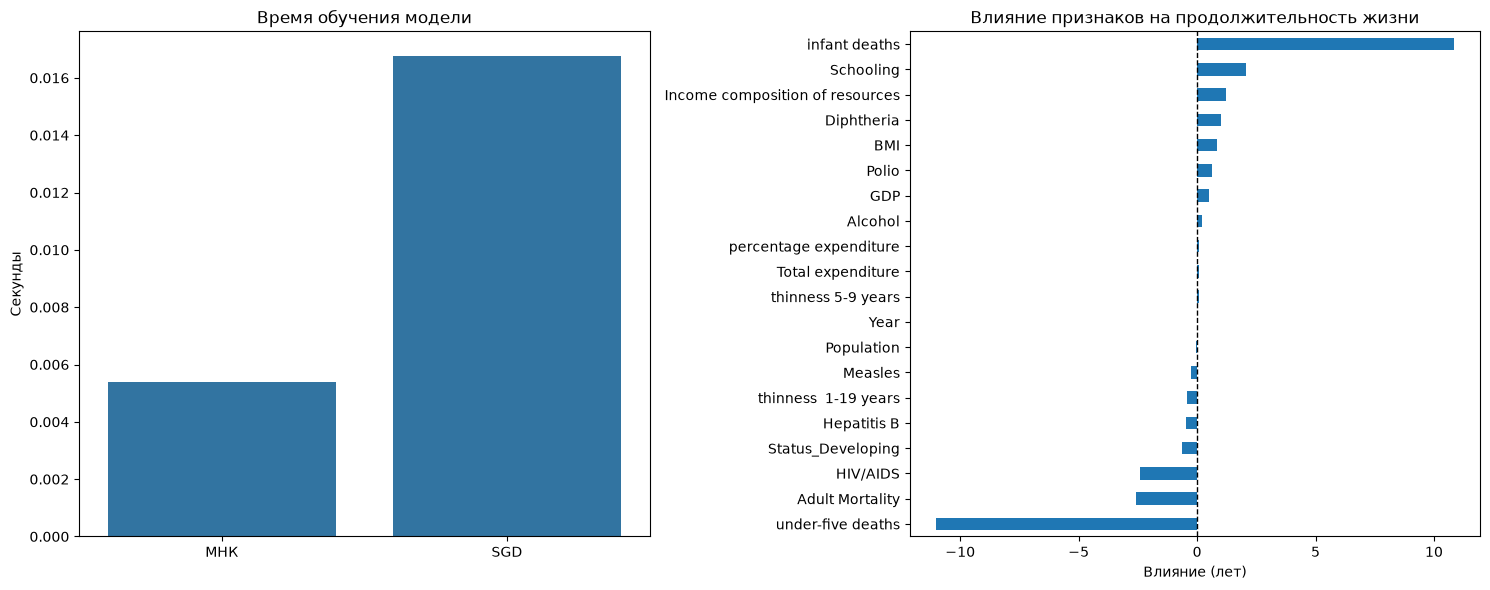

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Время
sns.barplot(
    x=["МНК", "SGD"],
    y=[time_ols, time_sgd],
    ax=axes[0],
)
axes[0].set_title("Время обучения модели")
axes[0].set_ylabel("Секунды")

# 2. Веса признаков
weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind="barh", ax=axes[1])
axes[1].set_title("Влияние признаков на продолжительность жизни")
axes[1].set_xlabel("Влияние (лет)")
axes[1].axvline(0, color="black", linestyle="--", lw=1)

plt.tight_layout()
plt.show()

Вывод: По графику весов видно, что наибольший положительный вклад в продолжительность жизни вносит уровень образования (`Schooling`). Также заметен вклад `Income composition of resources`. Самый сильный отрицательный вес у младенческой смертности (`infant deaths`) и взрослой смертности (`Adult Mortality`). Это полностью соответствует логике: чем выше смертность, тем ниже ожидаемая продолжительность жизни.

## Общий вывод по работе

В ходе работы выполнено прогнозирование продолжительности жизни на основе данных ВОЗ. На этапе подготовки данных удалён столбец с названиями стран и пропуски заполнены медианой. Задача сведена к бинарной классификации по медиане. Логистическая регрессия показала точность 0.8861, что говорит о хорошей разделимости стран на группы с высокой и низкой продолжительностью жизни.

При сравнении регрессионных моделей аналитический МНК показал качество R² = 0.82 при средней ошибке 3.91 года и времени обучения 0.0054 секунды. Итеративный SGD в текущей конфигурации не сошёлся: R² = -1.25, ошибка выросла до 13.96 лет, время обучения составило 0.0168 секунды. Это демонстрирует чувствительность градиентного спуска к настройке параметров. Анализ весов подтвердил логику данных: образование положительно влияет на продолжительность жизни, а младенческая и взрослая смертность - отрицательно. На данном объёме данных МНК оказался точнее и быстрее, однако для больших массивов необходимо уметь настраивать итеративные методы.

